# Step 1: Load the base training data

This notebook loads `train_base.parquet` into a pandas **DataFrame**, a table of rows and columns in Python. Each row represents one loan application.


In [1]:
from pathlib import Path
import pandas as pd

# The location of the Parquet file on your laptop.
data_path = Path(
    r"D:\Home Credit - Credit Risk Model Stability\data\parquet_files\train\train_base.parquet"
)

# Read the file and keep the table in a variable called train_base.
train_base = pd.read_parquet(data_path)

print(f"Loaded {train_base.shape[0]:,} rows and {train_base.shape[1]} columns.")

Loaded 1,526,659 rows and 5 columns.


## View the first five rows

`head()` displays the first five rows. The complete base table has already been loaded into `train_base`; this command only limits what is displayed.

In [2]:
train_base.head()

,case_id,date_decision,MONTH,WEEK_NUM,target
0,0,2019-01-03,201901,0,0
1,1,2019-01-03,201901,0,0
2,2,2019-01-04,201901,0,0
3,3,2019-01-03,201901,0,0
4,4,2019-01-04,201901,0,1


### What the columns mean

| Column | Meaning |
| --- | --- |
| `case_id` | Application identifier used to join other tables. |
| `date_decision` | Date of the application decision. |
| `MONTH` | Calendar month, such as `201901` for January 2019. |
| `WEEK_NUM` | Week index used to study performance over time. |
| `target` | Outcome to predict: `1` indicates default and `0` indicates no default. |


## Step 2: Understand and check the base data

This step is **exploratory data analysis (EDA)**: understanding the data before training a model. We will check the column types, missing values, duplicate applications, target balance, and changes across weeks.

Run the earlier loading cell first, then run these cells from top to bottom.

### 2.1 Inspect the data types

`info()` shows each column's type and the number of non-missing values. `int64` means whole numbers. An `object` column often contains text; the date column currently contains date strings.

In [3]:
train_base.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1526659 entries, 0 to 1526658
Data columns (total 5 columns):
 #   Column         Non-Null Count    Dtype 
---  ------         --------------    ----- 
 0   case_id        1526659 non-null  int64 
 1   date_decision  1526659 non-null  object
 2   MONTH          1526659 non-null  int64 
 3   WEEK_NUM       1526659 non-null  int64 
 4   target         1526659 non-null  int64 
dtypes: int64(4), object(1)
memory usage: 58.2+ MB


### 2.2 Convert the date column

Convert the date strings into actual datetime values so Python can compare dates and calculate time differences reliably. This changes the DataFrame in memory; it does not rewrite the source Parquet file.

In [4]:
train_base["date_decision"] = pd.to_datetime(
    train_base["date_decision"], format="%Y-%m-%d"
)

print("Date type:", train_base["date_decision"].dtype)
print("Earliest decision:", train_base["date_decision"].min().date())
print("Latest decision:", train_base["date_decision"].max().date())

Date type: datetime64[ns]
Earliest decision: 2019-01-01
Latest decision: 2020-10-05


### 2.3 Check missing values and duplicate applications

A missing value means a field has no recorded value. `isna()` identifies missing values and `sum()` counts them by column.

Each application should appear once in this base table. We check both repeated complete rows and repeated `case_id` values. These checks describe this table only; other tables can contain missing values or multiple history records per application.

In [5]:
quality_summary = pd.DataFrame({
    "data_type": train_base.dtypes.astype(str),
    "missing_count": train_base.isna().sum(),
    "missing_percent": train_base.isna().mean().mul(100).round(2),
})
quality_summary.index.name = "column"

print(f"Duplicate complete rows: {train_base.duplicated().sum():,}")
print(f"Duplicate application IDs: {train_base['case_id'].duplicated().sum():,}")
quality_summary

Duplicate complete rows: 0
Duplicate application IDs: 0


,data_type,missing_count,missing_percent
column,,,
case_id,int64,0,0.0
date_decision,datetime64[ns],0,0.0
MONTH,int64,0,0.0
WEEK_NUM,int64,0,0.0
target,int64,0,0.0


### 2.4 Understand the target balance

The target is the outcome we eventually want to predict: `0` means no default and `1` means default.

`value_counts()` counts applications in each outcome. The percentages tell us whether one outcome is much more common than the other.

In [6]:
target_summary = (
    train_base["target"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("target")
    .to_frame("applications")
)
target_summary["meaning"] = target_summary.index.map({0: "No default", 1: "Default"})
target_summary["percent"] = (
    target_summary["applications"] / len(train_base) * 100
).round(2)

target_summary[["meaning", "applications", "percent"]]

,meaning,applications,percent
target,,,
0,No default,1478665,96.86
1,Default,47994,3.14


The outcomes are **imbalanced**: defaults are much less common. The next calculation shows the accuracy of always predicting `0`, without learning anything. It demonstrates why accuracy alone would be misleading; it is not a trained model.

In [7]:
always_no_default_accuracy = train_base["target"].eq(0).mean()
print(f"Accuracy if every prediction is 'no default': {always_no_default_accuracy:.2%}")
print("That rule would identify none of the actual defaults.")

Accuracy if every prediction is 'no default': 96.86%
That rule would identify none of the actual defaults.


### 2.5 Summarize applications by week

`groupby()` collects rows belonging to the same week. We then calculate:

- **applications:** how many applications occurred in the week;
- **defaults:** how many of those applications have target `1`;
- **default rate:** the percentage with target `1`.

Because the target contains only 0 and 1, its sum counts defaults and its mean gives the default rate.

In [8]:
weekly_summary = (
    train_base.groupby("WEEK_NUM")
    .agg(
        applications=("case_id", "size"),
        defaults=("target", "sum"),
        default_rate=("target", "mean"),
    )
    .sort_index()
)
weekly_summary["default_rate_percent"] = weekly_summary["default_rate"] * 100

print(f"Weeks observed: {len(weekly_summary)}")
print(f"Week index: {weekly_summary.index.min()} to {weekly_summary.index.max()}")
weekly_summary[["applications", "defaults", "default_rate_percent"]].head().round(2)

Weeks observed: 92
Week index: 0 to 91


,applications,defaults,default_rate_percent
WEEK_NUM,,,
0,16735,400,2.39
1,18841,472,2.51
2,17476,465,2.66
3,16108,419,2.60
4,14309,404,2.82


### 2.6 Plot changes over time

The first chart shows application volume. The second shows the observed default rate, with the overall application-weighted default rate as a reference.

These charts describe the dataset. They do **not** measure a model's performance, and a week with fewer applications can have a less reliable rate estimate.

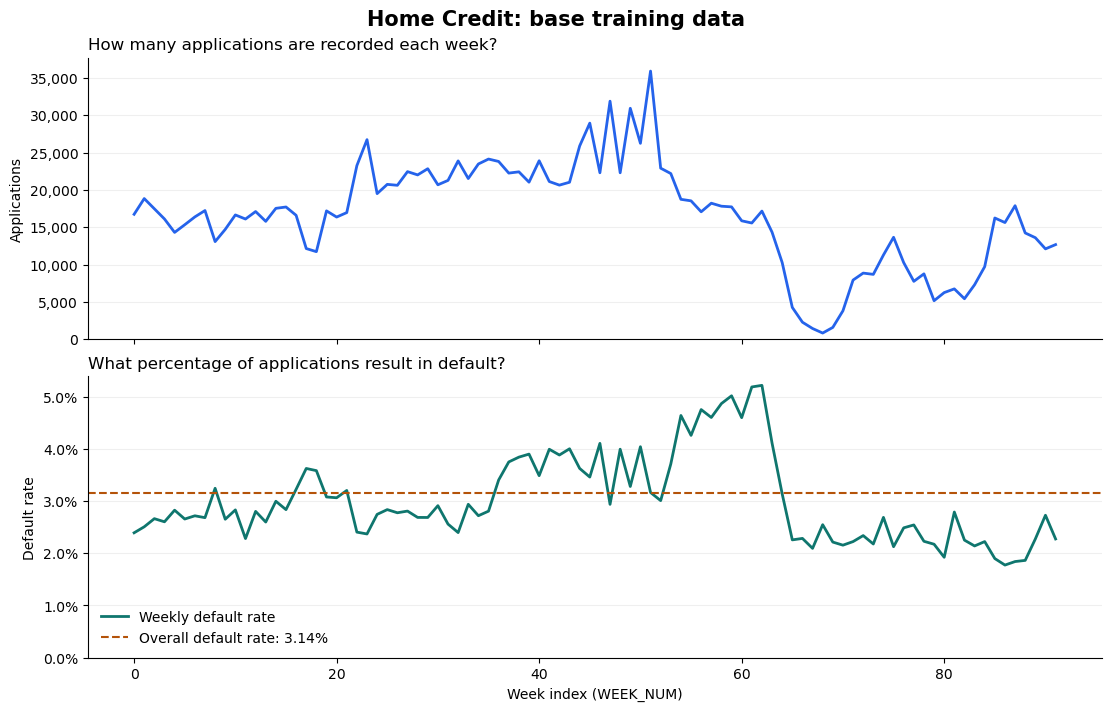

In [9]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter, PercentFormatter

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True, layout="constrained")

axes[0].plot(
    weekly_summary.index, weekly_summary["applications"],
    color="#2563EB", linewidth=2,
)
axes[0].set_title("How many applications are recorded each week?", loc="left")
axes[0].set_ylabel("Applications")
axes[0].yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
axes[0].set_ylim(bottom=0)

axes[1].plot(
    weekly_summary.index, weekly_summary["default_rate_percent"],
    color="#0F766E", linewidth=2, label="Weekly default rate",
)
overall_default_percent = train_base["target"].mean() * 100
axes[1].axhline(
    overall_default_percent, color="#B45309", linestyle="--", linewidth=1.5,
    label=f"Overall default rate: {overall_default_percent:.2f}%",
)
axes[1].set_title("What percentage of applications result in default?", loc="left")
axes[1].set_ylabel("Default rate")
axes[1].set_xlabel("Week index (WEEK_NUM)")
axes[1].yaxis.set_major_formatter(PercentFormatter(xmax=100))
axes[1].set_ylim(bottom=0)
axes[1].legend(loc="lower left", frameon=False)

for ax in axes:
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Home Credit: base training data", fontsize=15, fontweight="bold")

# Save a copy of the chart in the project's reports/figures folder.
project_dir = data_path.parents[3]
figure_dir = project_dir / "reports" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
figure_path = figure_dir / "base_weekly_overview.png"
fig.savefig(figure_path, dpi=150, facecolor="white")
plt.show()
plt.close(fig)

### What to learn from these results

- The base table has no missing values or duplicate application IDs, so these checks reveal no need to remove rows from it.
- Defaults account for about **3.14%** of applications. Later we will evaluate how well the model ranks risk using AUC and the competition's stability metric.
- Application counts and default rates change across the **92 weeks**. We should therefore evaluate future models on later weeks after training on earlier weeks.
- A changing default rate does not by itself prove that a model is unstable. We will need actual predictions to assess that.

**The next stage, after understanding these results:** select a few predictor columns from the two `train_static_0` files, concatenate those file parts, and join the resulting table to the base using `case_id`. The identifier is a join key, and `target` is the outcome; neither should be treated as an input feature.